In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import os

# Caminho para a pasta onde os dados foram extraídos
DATASET_DIR = "../data/doenca" 

BATCH_SIZE = 32
# A MobileNetV2 espera imagens quadradas de 224x224
IMG_SIZE = (224, 224) 

print("Carregando conjunto de TREINO:")
treino_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "treino"),
    shuffle=True, # Embaralha para o modelo não viciar na ordem
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
)

print("\nCarregando conjunto de VALIDAÇÃO:")
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "validacao"),
    shuffle=False, # Não precisamos embaralhar validação
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
)

print("\nCarregando conjunto de TESTE:")
teste_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "teste"),
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
)

class_names = treino_ds.class_names
print(f"\nClasses detectadas: {class_names}")

# Otimização de I/O focada em poupar memória RAM
AUTOTUNE = tf.data.AUTOTUNE
# O .cache() foi removido. O prefetch() já é suficiente para manter o fluxo contínuo!
treino_ds = treino_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
teste_ds = teste_ds.prefetch(buffer_size=AUTOTUNE)

Carregando conjunto de TREINO:
Found 1813 files belonging to 2 classes.

Carregando conjunto de VALIDAÇÃO:
Found 389 files belonging to 2 classes.

Carregando conjunto de TESTE:
Found 389 files belonging to 2 classes.

Classes detectadas: ['pinta_preta', 'saudavel']


In [2]:
# 1. Camada de Aumento de Dados (Data Augmentation)
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2),
    ],
    name="data_augmentation",
)

# 2. Carregando a MobileNetV2 pré-treinada
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False, # Remove a camada final original (que classificava 1000 objetos genéricos)
    weights='imagenet'
)

# Congelando os pesos da base para aproveitar o conhecimento prévio
base_model.trainable = False

# 3. Montando o modelo final
inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)

# A MobileNetV2 exige que os pixels (0 a 255) sejam normalizados entre -1 e 1
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
x = preprocess_input(x)

# Passando as imagens pela base congelada
x = base_model(x, training=False)

# Achata as características encontradas
x = layers.GlobalAveragePooling2D()(x)

# Dropout de 20% para forçar a rede a não decorar os dados (evita overfitting)
x = layers.Dropout(0.2)(x) 

# Camada de Saída: 1 único neurônio com Sigmoid (0 = Pinta Preta, 1 = Saudável)
outputs = layers.Dense(1, activation='sigmoid')(x)

model = keras.Model(inputs, outputs)

# Compilando o modelo
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

# Exibe o resumo da arquitetura
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Iniciando o treinamento da Baseline de Doenças...
Epoch 1/20


c:\Users\joaom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


57/57 ━━━━━━━━━━━━━━━━━━━━ 39s 604ms/step - accuracy: 0.8202 - loss: 0.4037 - val_accuracy: 0.9537 - val_loss: 0.1645
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 31s 543ms/step - accuracy: 0.9239 - loss: 0.2096 - val_accuracy: 0.9769 - val_loss: 0.1132
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 590ms/step - accuracy: 0.9498 - loss: 0.1551 - val_accuracy: 0.9692 - val_loss: 0.0968
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 41s 713ms/step - accuracy: 0.9586 - loss: 0.1355 - val_accuracy: 0.9794 - val_loss: 0.0794
Epoch 5/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 35s 614ms/step - accuracy: 0.9592 - loss: 0.1216 - val_accuracy: 0.9820 - val_loss: 0.0719
Epoch 6/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 36s 636ms/step - accuracy: 0.9630 - loss: 0.1048 - val_accuracy: 0.9871 - val_loss: 0.0642
Epoch 7/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 595ms/step - accuracy: 0.9597 - loss: 0.1118 - val_accuracy: 0.9897 - val_loss: 0.0595
Epoch 8/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 37s 647ms/step - accuracy: 0.9586 - loss: 0.1051 - val_accuracy: 0.987

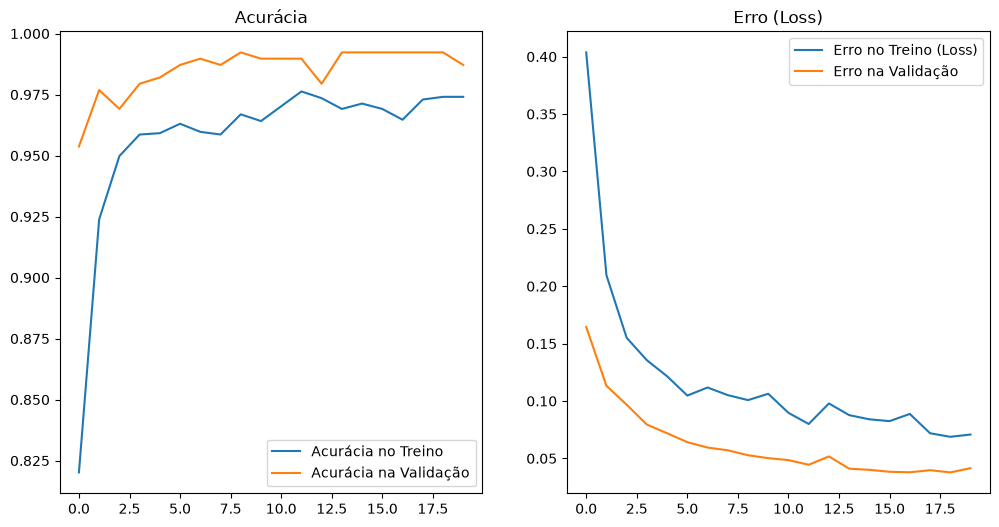

In [3]:
# Callbacks para otimizar o treinamento
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', # Fica de olho no erro da validação
        patience=5,         # Se não melhorar por 5 épocas seguidas, ele para
        restore_best_weights=True # Garante que vai salvar a melhor versão, não a última
    )
]

EPOCHS = 20 # Número máximo de vezes que ele vai ver o dataset inteiro

print("Iniciando o treinamento da Baseline de Doenças...")
history = model.fit(
    treino_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Plotando os gráficos de aprendizado
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Acurácia no Treino')
plt.plot(epochs_range, val_acc, label='Acurácia na Validação')
plt.legend(loc='lower right')
plt.title('Acurácia')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Erro no Treino (Loss)')
plt.plot(epochs_range, val_loss, label='Erro na Validação')
plt.legend(loc='upper right')
plt.title('Erro (Loss)')
plt.show()